In [9]:
from upconversion_models import AndersonModel, AndersonModelUnfolded, AndersonModelUnfoldedTwice, AndersonModelUnfoldedTwiceETU69, cmap
from upconversion_models.jablonski_patch import (
    Simulator,
    EmissionTransform,
    LineEnergyPost,
    SteadyState,
    piecewise,
)
from upconversion_models.utils import hc, k
from poincare import solvers
from pint import get_application_registry

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

u = get_application_registry()

In [10]:
def mismatch69(m6s):
    # 6h->9 is 650 cm-1 larger; 0 = resonant
    m6h = m6s + 650 if m6s > 0 else 0
    return {
        AndersonModelUnfoldedTwiceETU69.etu6s9._mismatch_wavenumber: m6s / u.cm,
        AndersonModelUnfoldedTwiceETU69.etu6h9._mismatch_wavenumber: m6h / u.cm,
    }


lines_and = [
    # ("line_rad81", 410, cmap["b"]),
    ("line_rad61", "6", "gray"),
    # ("line_rad51", 655, cmap["r"]),
    # ("line_rad31", 1000, "black"),
]

lines_unf = [
    # ("line_rad81", 410, cmap["b"]),
    ("line_rad6s1", "6s", cmap["y"]),
    ("line_rad6h1", "6h", cmap["g"]),
    # ("line_rad51", 655, cmap["r"]),
    # ("line_rad31", 1000, "black"),
]


base = (
    (
        "anderson",
        AndersonModel,
        {},
        lines_and,
    ),
)

cases = [

    (
        "unfolded",
        AndersonModelUnfolded,
        {AndersonModelUnfolded.k_therm: 2.29e6 / u.s},  # from suta's paper
        lines_unf,
    ),
    (
        "unfolded_twice",
        AndersonModelUnfoldedTwice,
        {AndersonModelUnfoldedTwice.k_therm: 2.29e6 / u.s},  # from suta's paper
        lines_unf,
    ),

    (
        "non_resonant_etu69",
        AndersonModelUnfoldedTwiceETU69,
        mismatch69(2400),
        lines_unf,
    ),
]

In [11]:
def get_time_resolved(M,d = {}):
    sim = (
        Simulator(M())
        .with_transform(EmissionTransform("emission"), append=True)
        .with_solver(solvers.LSODA(rtol=1e-10, atol=1e-10))
        .with_post(LineEnergyPost())
    )

    photon_wavelength = 943 * u.nm

    pulse_density = 66e-3 * u.J / u.cm**2
    pulse_width = 1e-5 * u.s
    pulse_height = pulse_density / pulse_width / (hc / photon_wavelength)
    pulse = {
        0 * u.s: {M.photon_flux: pulse_height},
        pulse_width: {M.photon_flux: 0 / u.s / u.cm**2},
    }

    res = piecewise(
        sim.with_values({M.yb_cross_section: 2.3e-21 * u.cm**2} | d),
        events=pulse,
        save_at=np.linspace(0, 2e-3, 1000) * u.s,
    )

    res = res.pint.dequantify()

    df = res.to_dataframe()
    df.index = (df.index) * 1e3
    return df

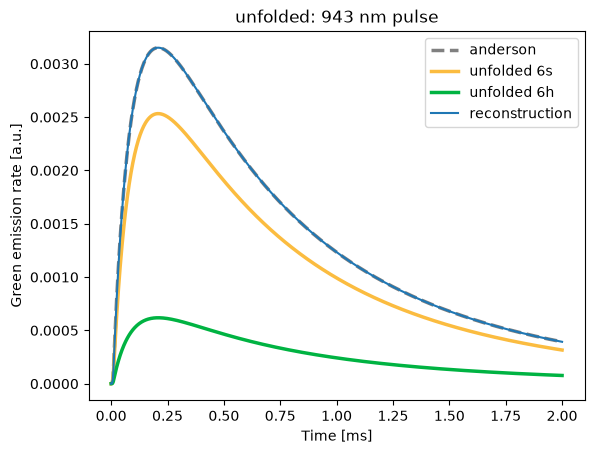

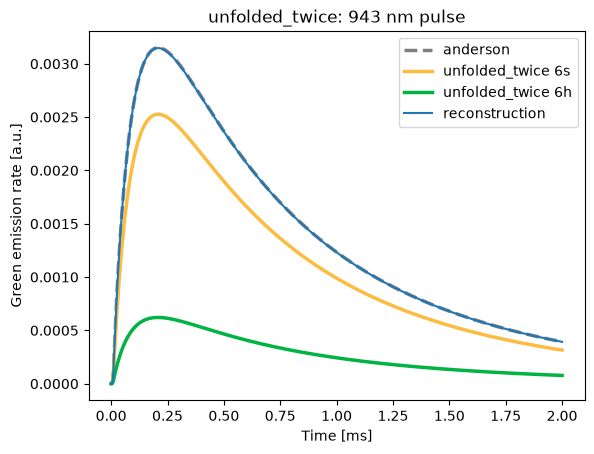

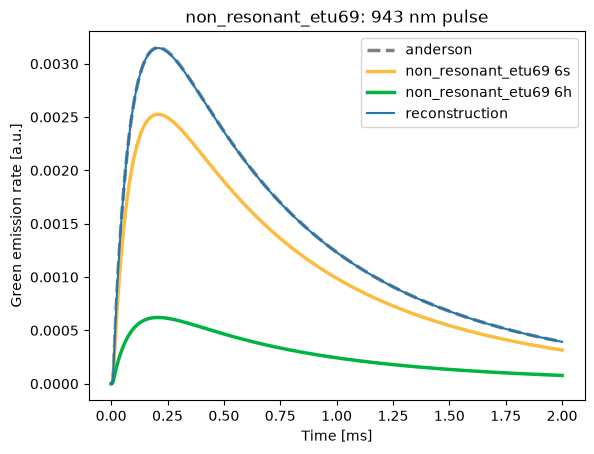

In [12]:
bdf = get_time_resolved(AndersonModel)


for case_name, M, d, lines in cases:
    plt.figure()
    s = bdf['line_rad61']
    s.plot(color="gray", ls = "--",label=f"anderson", lw=2.5)

    df = get_time_resolved(M,d)
    for name, wv, color in lines:
        s = df[name]
        s.plot(color=color, label=f"{case_name} {wv}", lw=2.5)
    s = df[["line_rad6s1","line_rad6h1"]].sum(axis=1)
    s.plot(label="reconstruction")

    plt.title(f"{case_name}: 943 nm pulse")
    plt.xlabel("Time [ms]")
    plt.ylabel("Green emission rate [a.u.]")
    plt.legend()


## Boltzmann ratio

/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/matplotlib/cbook.py:1407: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asanyarray(x, float)
/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/pandas/core/construction.py:644: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)
/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/matplotlib/cbook.py:1407: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asanyarray(x, float)
/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/pandas/core/construction.py:644: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)
/Users/ramir

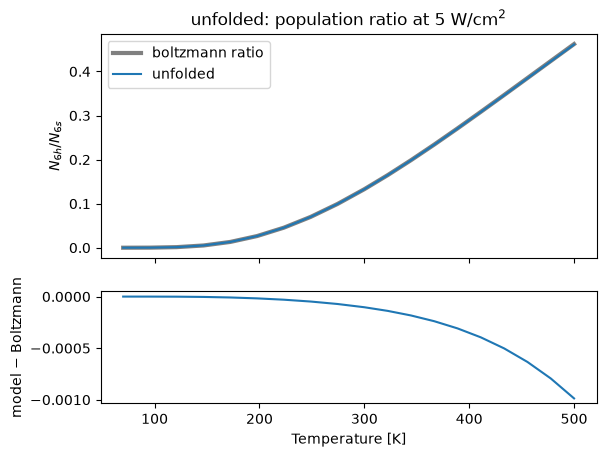

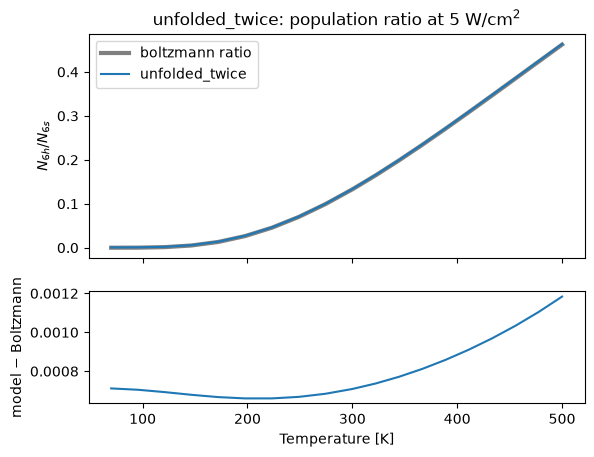

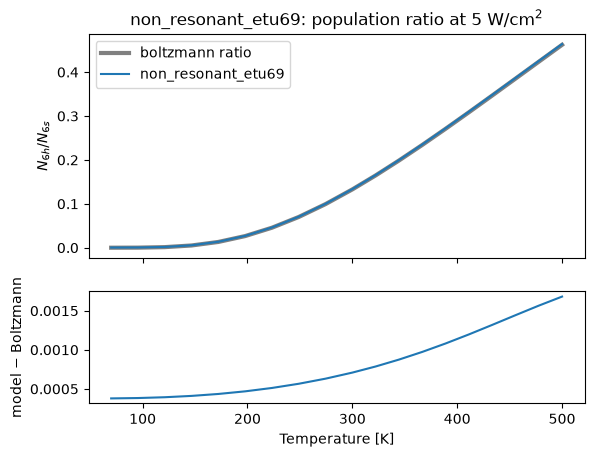

In [13]:
def F(T):
    return 3 * np.exp(-1 * 650 / u.cm * hc / (k * T))


Ts = np.concatenate([np.linspace(70, 300, 10)[:-1], np.linspace(300, 500, 10)]) * u.K
FTs = F(Ts)


for case_name, M, d, lines in cases:
    fig, axs = plt.subplots(2, height_ratios=(2, 1), sharex=True)

    axs[0].plot(Ts, FTs, label="boltzmann ratio", color="gray", lw=3)

    sim = (
        Simulator(M())
        .with_transform(EmissionTransform("emission"), append=True)
        .with_solver(solvers.LSODA(rtol=1e-10, atol=1e-10))
    )

    df = (
        SteadyState()
        .sweep(
            sim.with_values(
                {M.photon_flux: 5 * u.W / u.cm**2 / (hc / (980 * u.nm))} | d
            ),
            variable=M.T,
            values=Ts,
        )
        .to_dataframe()
    )

    df["R"] = df["Er6h"] / df["Er6s"]
    df["residuals"] = df["R"] - FTs
    df["R"].plot(label=case_name, ax=axs[0])
    df["residuals"].plot(ax=axs[1])

    axs[0].set_title(f"{case_name}: population ratio at 5 W/cm$^2$")
    axs[0].set_ylabel("$N_{6h}/N_{6s}$")
    axs[1].set_ylabel("model − Boltzmann")
    axs[1].set_xlabel("Temperature [K]")
    axs[0].legend()

## Temperature dependance

/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/matplotlib/cbook.py:1407: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asanyarray(x, float)
/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/matplotlib/cbook.py:1407: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asanyarray(x, float)
/Users/ramirohar/Documents/tesis/upconversion_models/.pixi/envs/default/lib/python3.13/site-packages/matplotlib/cbook.py:1407: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asanyarray(x, float)


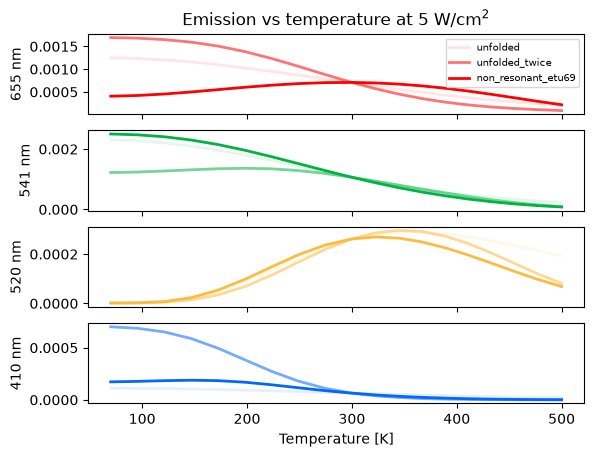

In [14]:
fig, axs = plt.subplots(4, sharex=True)

alphas = np.linspace(0.1, 1, len(cases))

for i, (case_name, M, d, lines) in enumerate(cases):
    sim = (
        Simulator(M())
        .with_transform(EmissionTransform("emission"), append=True)
        .with_solver(solvers.LSODA(rtol=1e-10, atol=1e-10))
    )

    df = (
        SteadyState()
        .sweep(
            sim.with_values({M.photon_flux: 5 * u.W / u.cm**2 / (hc / (980 * u.nm))}),
            variable=M.T,
            values=Ts,
        )
        .to_dataframe()
    )

    axs[0].plot(
        Ts, df["line_rad51"], alpha=alphas[i], label=case_name, lw=2, c="#ff0000"
    )
    axs[1].plot(
        Ts, df["line_rad6s1"], alpha=alphas[i], label=case_name, lw=2, c="#00b342"
    )
    axs[2].plot(
        Ts, df["line_rad6h1"], alpha=alphas[i], label=case_name, lw=2, c="#fbbc40"
    )
    axs[3].plot(
        Ts, df["line_rad81"], alpha=alphas[i], label=case_name, lw=2, c="#0068ff"
    )

for ax, label in zip(axs, ["655 nm", "541 nm", "520 nm", "410 nm"]):
    ax.set_ylabel(label)
axs[0].set_title("Emission vs temperature at 5 W/cm$^2$")
axs[-1].set_xlabel("Temperature [K]")
axs[0].legend(fontsize=7)

## 6s→9 mismatch vs Yu 2014


In [ ]:
from upconversion_models import AndersonModelUnfoldedTwiceETU69 as M69

yu = pd.read_csv("../sources/yu2014_digitized/fig4_bulk.csv", index_col="T")  # Yu 2014 Fig. 4, bulk
# normalize each line at its digitized point closest to 300 K
yu_ref = {col: yu[col].dropna().index[np.argmin(abs(yu[col].dropna().index - 300))] for col in yu}

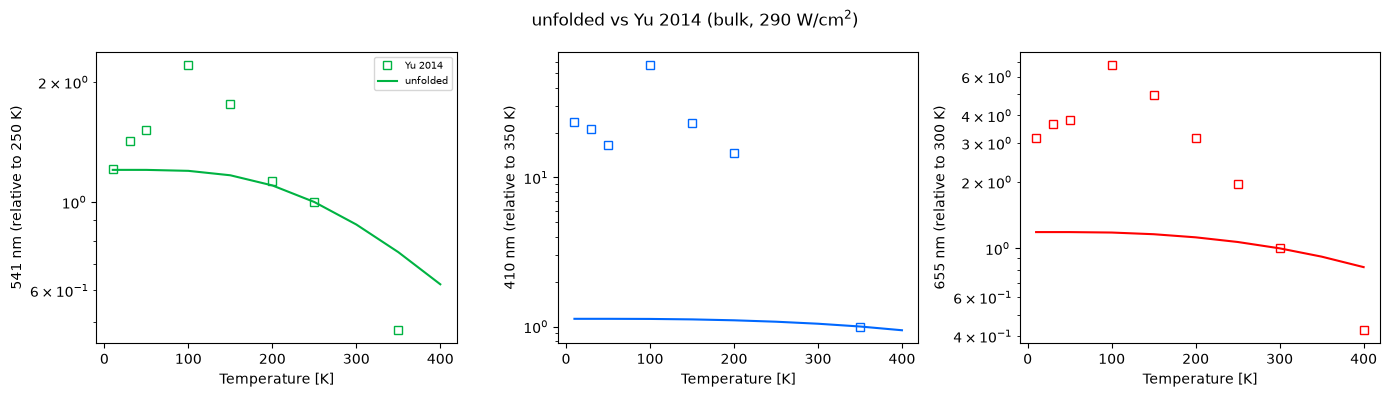

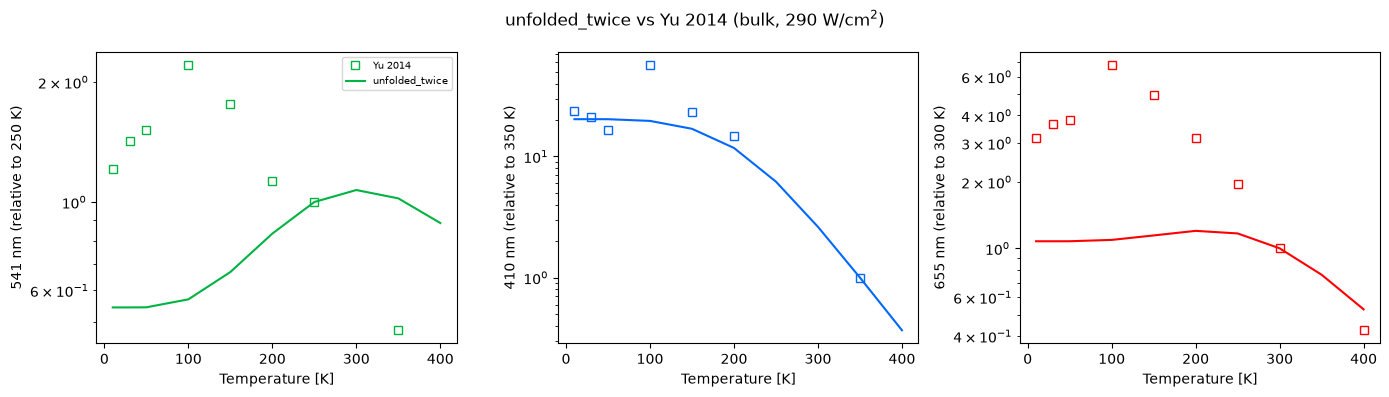

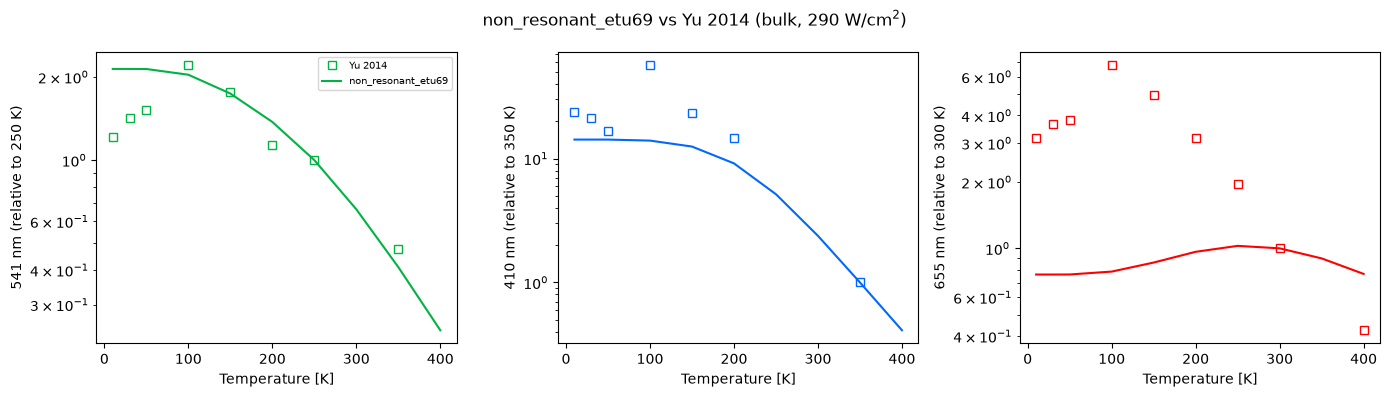

In [16]:
cols = [
    ("S", cmap["g"], "541 nm"),
    ("blue", cmap["b"], "410 nm"),
    ("red", cmap["r"], "655 nm"),
]



for i, (case_name, M, d, lines) in enumerate(cases):
    fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharex=True)

    for ax, (col, color, label) in zip(axs, cols):
        ax.semilogy(
            yu.index,
            yu[col] / yu.loc[yu_ref[col], col],
            "s",
            color=color,
            mfc="none",
            label="Yu 2014",
        )
        ax.set_ylabel(f"{label} (relative to {yu_ref[col]} K)")
        ax.set_xlabel("Temperature [K]")


    sim = (
        Simulator(M())
        .with_transform(EmissionTransform("emission"), append=True)
        .with_solver(solvers.LSODA(rtol=1e-10, atol=1e-10))
    )

    df = (
        SteadyState()
        .sweep(
            sim.with_values(
                {M.photon_flux: 290 * u.W / u.cm**2 / (hc / (980 * u.nm))} | d
            ),
            variable=M.T,
            values=yu.index.to_numpy() * u.K,
        )
        .to_dataframe()
    )

    df["S"] = df["line_rad6s1"]
    df["blue"] = df["line_rad81"]
    df["red"] = df["line_rad51"]
    for ax, (col, color, label) in zip(axs, cols):
        ax.semilogy(
            df.index,
            df[col] / df[col].iloc[list(yu.index).index(yu_ref[col])],
            color=color,
            label=case_name,
        )

    fig.suptitle(f"{case_name} vs Yu 2014 (bulk, 290 W/cm$^2$)")
    axs[0].legend(fontsize=7)
    fig.tight_layout()